# Skeleton extraction with MediaPipe Pose

**Goals of this notebook:**
1. Extract the patient's body landmarks from every video with MediaPipe Pose
2. Check the quality of the landmarks visually and with numbers
3. Decide whether MediaPipe is reliable enough for this dataset

## 1. Pose estimation model: MediaPipe Pose Landmarker (heavy)
MediaPipe Pose finds **33 body landmarks** per person in each frame.
The **heavy** model (the most accurate of the three sizes: lite, full, heavy) is used.
The leg landmarks used in this project:

| Index | Landmark |
|---|---|
| 23, 24 | left hip, right hip |
| 25, 26 | left knee, right knee |
| 27, 28 | left ankle, right ankle |


In [ ]:
# Install MediaPipe and download its pose model
!pip install -q mediapipe
!wget -q -O pose_landmarker_heavy.task \
  https://storage.googleapis.com/mediapipe-models/pose_landmarker/pose_landmarker_heavy/float16/latest/pose_landmarker_heavy.task
import cv2
import numpy as np
import mediapipe as mp
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision

def create_landmarker():
    options = vision.PoseLandmarkerOptions(
        base_options=mp_python.BaseOptions(model_asset_path="pose_landmarker_heavy.task"),
        running_mode=vision.RunningMode.VIDEO,   # video mode: uses previous frames to track better
        num_poses=2,
        min_pose_detection_confidence=0.2,   # default is 0.5; lower = detects more easily
        min_pose_presence_confidence=0.2,
        min_tracking_confidence=0.2,
       )
    return vision.PoseLandmarker.create_from_options(options)

## 2. Download the dataset


In [ ]:
# Ask the Figshare API for the list of files in the dataset.
import requests

article_id = 14984667
response = requests.get(f"https://api.figshare.com/v2/articles/{article_id}")
files = response.json()["files"]

In [ ]:
# Download every file of the dataset into /content/data.

!mkdir -p /content/data

for f in files:
    name = f["name"]
    url = f["download_url"]
    !wget -c -q --show-progress -O "/content/data/{name}" "{url}"

/content/data/Video 100%[===================>]   4.67G  13.9MB/s    in 5m 53s  
/content/data/PDFEi 100%[===================>]  12.01K  --.-KB/s    in 0s      
/content/data/IMU.z 100%[===================>] 152.50M  14.1MB/s    in 12s     


In [ ]:
# Unzip all downloaded zip files, then delete the zips to save disk space.
!cd /content/data && for z in *.zip; do unzip -q "$z" && rm "$z"; done
!ls -lh /content/data

total 32K
drwxr-xr-x 2 root root  12K Oct 30 05:16 IMU
-rw-r--r-- 1 root root  13K Nov 21  2021 PDFEinfo.csv
drwxr-xr-x 2 root root 4.0K Oct 30 05:17 Videos


In [ ]:
# Main data folder.
from pathlib import Path

DATA_DIR= Path('/content/data')

## 3. Skeleton extraction function
For every frame of a video, the function:
1. **Crops the central vertical strip** of the image (the 20% on each side is removed). The patient stands in the middle, while the clinician is usually at the side, so the crop helps the model focus on the patient.
2. **Runs MediaPipe** on the cropped image.
3. **Selects the patient:** if 2 people are found, it keeps the one whose ankles are closest to the centre of the strip.
4. **Converts x back** from "fraction of the cropped image" to "fraction of the full image", so the landmarks can be drawn on the original video.

If no person is found, the frame is filled with NaN. This keeps **one row per video frame**, so the skeleton stays aligned in time with the video.

Output: an array of shape **(number of frames, 33 landmarks, 4 values: x, y, z, visibility)** and the number of frames read.

In [ ]:
# Read a video frame by frame and return the patient's 33 landmarks for every frame.
# Returns (skeleton, n_frames): skeleton has shape (n_frames, 33, 4) = x, y, z, visibility.
def extract_skeleton(video_path):
    landmarker = create_landmarker()   # a new one per video
    cap = cv2.VideoCapture(str(video_path))
    fps = cap.get(cv2.CAP_PROP_FPS)
    frames = []
    frame_index = 0

    while True:
        ok, frame = cap.read()
        if not ok:
            break
        #Cut out the central vertical strip
        height, width = frame.shape[:2]
        distance2edge=0.2
        x_start = int(width * distance2edge)
        x_end= int(width * (1-distance2edge))
        frame_cropped = frame[:, x_start:x_end]
        crop_width = x_end - x_start

        frame_rgb = cv2.cvtColor(frame_cropped, cv2.COLOR_BGR2RGB)
        mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=frame_rgb)

        timestamp_ms = int(frame_index * 1000 / fps)

        result = landmarker.detect_for_video(mp_image, timestamp_ms)

        if not result.pose_landmarks:
           array=np.full((33, 4), np.nan)
        else:
           #keep the one whose ankles (joints 27 and 28) are closest to the centre of the strip (x = 0.5)
           patient=min(result.pose_landmarks,key=lambda lm:abs((lm[27].x+lm[28].x)/2-0.5))
           array = np.array([[lm.x, lm.y, lm.z, lm.visibility] for lm in patient])

            #Convert x from "fraction of the cropped frame" to "fraction of the full frame"
            #    pixel in full frame = x0 + x * crop_width
           array[:, 0] = ( x_start + array[:, 0] * crop_width) / width
        frames.append(array)

        frame_index += 1

    cap.release()
    landmarker.close()
    return (np.stack(frames), frame_index) if frames else (np.empty((0, 33, 4)),0)

## 4. Test on one video

In [ ]:
# Run the extraction on one video.
skeleton_sample, n_frames=extract_skeleton('/content/data/Videos/PDFE01_1.mp4')
print("skeleton_sample:", skeleton_sample.shape, " n_frames:", n_frames)

skeleton_sample: (3598, 33, 4)  n_frames: 3598


**Result:** shape (3598, 33, 4). The 3,598 frames match the number of frames in the video, so no frame was lost.

## 5. Visual quality check
Numbers alone can hide errors (for example, landmarks placed on the wrong person). The 6 leg landmarks (23–28) are drawn on 3 frames (start, middle, end) to check by eye whether they sit on the **patient's** legs. Only landmarks with visibility ≥ 0.5 are drawn.

In [ ]:
# Draw the 6 leg landmarks (23-28) on the first, middle, and last frame of a video.
import os
import matplotlib.pyplot as plt

def display_joint(video_path):

    video=cv2.VideoCapture(video_path)
    skeleton, n_frames=extract_skeleton(video_path)
    n_frames = len(skeleton)

    for n in [0, n_frames // 2, n_frames - 1]:
        video.set(cv2.CAP_PROP_POS_FRAMES, n)   # jump directly to frame n
        ok, frame = video.read()
        if not ok:
           continue
        height, width = frame.shape[:2]
        for j in range (23,29):
              x=skeleton[n,j,0]
              y=skeleton[n,j,1]
              vis = skeleton[n,j,3]
              if np.isnan(x) or np.isnan(y) or vis <0.5:
                continue
              pixel_x = int(x * width)
              pixel_y = int(y * height)
              cv2.circle(frame, (pixel_x, pixel_y), 5, (0, 255, 0), -1)
        plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        plt.title(f"frame_number = {n}")
        plt.axis("off")
        plt.show()
    video.release()

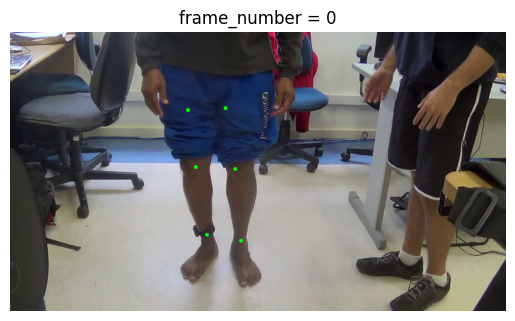

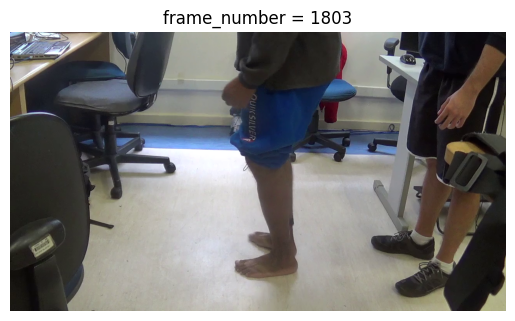

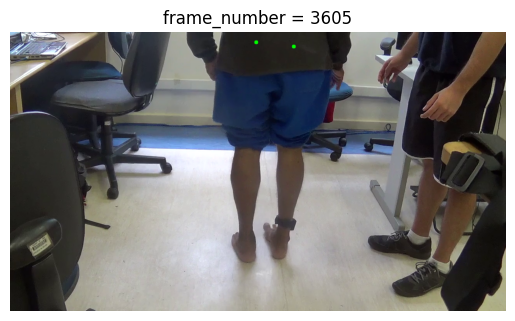

In [ ]:
# Visual check on PDFE16_2.
display_joint('/content/data/Videos/PDFE16_2.mp4')

**Result:** in frame 0 (patient facing the camera), all 6 leg landmarks are drawn and sit on the patient’s legs. In frame 1803 (side view), no leg landmark has visibility ≥ 0.5, so nothing is drawn. In frame 3605 (back view), only the 2 hips are drawn; the knees and ankles are missing. The clinician is not selected. MediaPipe detects the legs well only when the patient faces the camera.

## 6. Detection rate and ankle visibility

In [ ]:
# Count the frames where no person was found (landmark 0 is NaN),
# and the average visibility of the two ankles (27, 28).
skeleton, n = extract_skeleton('/content/data/Videos/PDFE16_2.mp4')
no_person = np.isnan(skeleton[:, 0, 0]).sum()
print(f"Frames with no person detected: {no_person} of {n}")
print("Average visibility, left ankle (27):", np.nanmean(skeleton[:, 27, 3]))
print("Average visibility, right ankle (28):", np.nanmean(skeleton[:, 28, 3]))

Frames with no person detected: 407 of 3606
Average visibility, left ankle (27): 0.3887512452677053
Average visibility, right ankle (28): 0.4274615022001082


**Result:** no person was found in **407 of 3,606 frames (11%)**. When a person was found, the average ankle visibility was only **0.39 (left)** and **0.43 (right)**, below the 0.5 threshold. MediaPipe has difficulty with these lower-body-only videos, even with lowered thresholds and cropping.

## 7. Extract and save the skeletons of all videos
To measure the detection quality over the whole dataset, all videos are processed and saved to Google Drive (one `.npy` file per video).

In [ ]:
# Connect Google Drive to save the results permanently.
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Extract the skeleton of every video and save it as <video name>.npy on Drive.
# Videos that already have a saved file are skipped, so the loop can continue
# where it stopped if Colab disconnects.
skeleton_mediapipe ='/content/drive/MyDrive/skeleton_mediapipe'
os.makedirs(skeleton_mediapipe,exist_ok=True)

for file in sorted(os.listdir('/content/data/Videos')):
    if not file.lower().endswith('.mp4'):
       continue

    video_name = os.path.splitext(file)[0]
    video_skeleton_file = os.path.join(skeleton_mediapipe, f"{video_name}.npy")

    # Skip videos that were already processed
    if os.path.exists(video_skeleton_file):
        print(f"Skipping {file} (already saved)")
        continue
    video_path= os.path.join('/content/data/Videos', file)
    skeleton, n_frames=extract_skeleton(video_path)

    # Save to a temp file first, then rename (safe against disconnects)
    tmp_file = video_skeleton_file + ".tmp.npy"
    np.save(tmp_file, skeleton)
    os.replace(tmp_file, video_skeleton_file)

Skipping PDFE01_1.mp4 (already saved)
Skipping PDFE01_2.mp4 (already saved)
Skipping PDFE02_1.mp4 (already saved)
Skipping PDFE03_1.mp4 (already saved)
Skipping PDFE03_2.mp4 (already saved)
Skipping PDFE03_3.mp4 (already saved)
Skipping PDFE04_1.mp4 (already saved)
Skipping PDFE05_1.mp4 (already saved)
Skipping PDFE05_2.mp4 (already saved)
Skipping PDFE06_1.mp4 (already saved)
Skipping PDFE06_2.mp4 (already saved)
Skipping PDFE07_1.mp4 (already saved)
Skipping PDFE07_2.mp4 (already saved)
Skipping PDFE07_3.mp4 (already saved)
Skipping PDFE08_1.mp4 (already saved)
Skipping PDFE09_1.mp4 (already saved)
Skipping PDFE09_2.mp4 (already saved)
Skipping PDFE10_1.mp4 (already saved)
Skipping PDFE10_2.mp4 (already saved)
Skipping PDFE10_3.mp4 (already saved)
Skipping PDFE11_1.mp4 (already saved)
Skipping PDFE11_2.mp4 (already saved)
Skipping PDFE12_1.mp4 (already saved)
Skipping PDFE13_1.mp4 (already saved)
Skipping PDFE14_1.mp4 (already saved)
Skipping PDFE14_2.mp4 (already saved)
Skipping PDF

## 8. Quality table over the 71 trials
The **saved files** are checked for the 71 trials with both video and IMU:
- `video_frames` – number of frames in the video
- `skeleton_frames` – number of frames in the saved skeleton; must equal `video_frames` (a difference of 1–2 frames can come from the video metadata)
- `%_no_person` – % of frames where no person was detected
- `%_legs_ok` – % of frames where **all 6 leg landmarks** (23–28) have visibility > 0.5

In [ ]:
# frame_difference = video_frames - skeleton_frames (should be about 0).
# Build a quality table from the saved skeleton files (71 trials).

import pandas as pd
results=[]

for file in os.listdir('/content/data/Videos'):
    if not file.lower().endswith('.mp4'):
       continue
    trial=os.path.splitext(file)[0]
    if trial in ["PDFE10_3", "PDFE30_3"]:       # no IMU, not used
       continue

    # Number of frames in the video
    cap = cv2.VideoCapture(os.path.join('/content/data/Videos', file))
    video_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    cap.release()

    # Load the saved skeleton
    skeleton = np.load(os.path.join(skeleton_mediapipe, f"{trial}.npy"))
    skeleton_frames=len(skeleton)
    no_person = np.isnan(skeleton[:, 0, 0]).sum()
    percent_no_person=(no_person/len(skeleton))*100
    percent_legs_ok=(skeleton[:, 23:29, 3] > 0.5).all(axis=1).mean() * 100
    results.append({"trial": trial,"video_frames": video_frames,"skeleton_frames":skeleton_frames,"%_no_person":percent_no_person,"%_legs_ok":percent_legs_ok})

results_df=pd.DataFrame(results)
results_df["frame_difference"] = results_df["video_frames"] - results_df["skeleton_frames"]

print(results_df.describe())
print(results_df.sort_values("%_legs_ok").head(5))    # the 5 worst trials


       video_frames  skeleton_frames  %_no_person  %_legs_ok  frame_difference
count     71.000000        71.000000    71.000000  71.000000         71.000000
mean    3604.084507      3604.014085    18.292528  13.645656          0.070423
std       51.678331        51.674944    11.561567  10.160338          0.257679
min     3360.000000      3360.000000     0.627901   1.444444          0.000000
25%     3605.500000      3605.500000    10.013889   7.456402          0.000000
50%     3610.000000      3610.000000    16.840580  12.254495          0.000000
75%     3619.000000      3619.000000    25.107872  15.775434          0.000000
max     3688.000000      3688.000000    50.611176  60.636238          1.000000
       trial  video_frames  skeleton_frames  %_no_person  %_legs_ok  \
2   PDFE21_3          3600             3600     4.972222   1.444444   
51  PDFE34_1          3615             3615    22.517289   2.351314   
34  PDFE29_1          3436             3436    50.611176   2.677532   
68  P

**Result**: all 71 trials were checked.

-`frame_difference`: 0 or 1 for all trials, so the saved skeletons have one row per video frame.

-`%_no_person`: no person was detected in 18.3% of frames on average (median 16.8%), and up to 50.6% in the worst trial (PDFE29_1).

-`%_legs_ok`: all 6 leg landmarks (hips, knees, ankles) had visibility > 0.5 in only 13.6% of frames on average (median 12.3%, maximum 60.6%).

The 5 worst trials are PDFE21_3 (1.4%), PDFE34_1 (2.4%), PDFE29_1 (2.7%), PDFE19_2 (3.1%), and PDFE11_2 (3.7%).

MediaPipe does not reliably detect the legs in this dataset: even in its best trial, all leg landmarks are visible in fewer than two thirds of the frames.

## Summary and decision
- The videos show the patient only from the **thighs down**. MediaPipe first locates a person using the face and upper body, so it often fails on these videos.
- On PDFE16_2, no person was found in 11% of frames, and the average ankle visibility was only about 0.4, even with the heavy model, lowered thresholds, and cropping.
- Over all 71 trials: no person was found in 18.3% of frames on average (up to 50.6%), and all 6 leg landmarks were visible in only 13.6% of frames on average.

**Decision:** MediaPipe is **not reliable enough** for this dataset. A second pose estimator, **YOLO11 pose**, which detects people without needing the face, was tested next (see the notebook `skeletons_yolo`) and was selected for the project.